# Cookie Cats: moving the first gate from level 30 to level 40
**Decision:** ship `gate_40` or keep `gate_30`?
**Primary metric:** `retention_7`, the share of players who played on day 7 after install.
**Secondary metric:** `retention_1`. **Guardrail:** `sum_gamerounds`, rounds played in the first 14 days.
**Data:** 90,189 players randomised at install, assigned 50/50 by design (`data/cookie_cats.csv`; Tactile Entertainment via the DataCamp/Kaggle "Mobile Games A/B Testing" project).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from expkit import *
df = pd.read_csv('data/cookie_cats.csv'); A, B = 'gate_30', 'gate_40'
assert df.userid.is_unique and df.notna().all().all()
n = df.version.value_counts()[[A, B]]; n

version
gate_30    44700
gate_40    45489
Name: count, dtype: int64

## 1. Validity: sample-ratio mismatch (chi-square vs planned 50/50)

In [2]:
chi2, p_srm = srm_test(n[A], n[B]); print(f'chi2={chi2:.2f}, p={p_srm:.4f}')

chi2=6.90, p=0.0086


## 2. Power: minimum detectable effect (alpha=0.05 two-sided, power=0.8) at the achieved n

In [3]:
base7 = df[df.version==A].retention_7.mean(); base1 = df[df.version==A].retention_1.mean()
print(f'MDE retention_7: {mde(base7, int(n.min()))*100:.2f} pp on base {base7*100:.2f}%')
print(f'MDE retention_1: {mde(base1, int(n.min()))*100:.2f} pp on base {base1*100:.2f}%')

MDE retention_7: 0.74 pp on base 19.02%
MDE retention_1: 0.93 pp on base 44.82%


## 3. Effect: pooled z-test, with a Newcombe (Wilson) 95% CI for gate_40 minus gate_30

In [4]:
res = {}
for m in ['retention_1', 'retention_7']:
    g = df.groupby('version')[m].agg(['sum', 'count'])
    res[m] = two_prop_test(g.loc[A,'sum'], g.loc[A,'count'], g.loc[B,'sum'], g.loc[B,'count'])
out = pd.DataFrame({k: {'gate_30 %': v.p_a*100, 'gate_40 %': v.p_b*100, 'diff pp': v.diff*100, 'CI low pp': v.ci_low*100,
                       'CI high pp': v.ci_high*100, 'rel lift %': v.rel_lift*100, 'p': v.p_value} for k, v in res.items()}).T
out.round(4)

,gate_30 %,gate_40 %,diff pp,CI low pp,CI high pp,rel lift %,p
retention_1,44.8188,44.2283,-0.5905,-1.2392,0.0582,-1.3176,0.0744
retention_7,19.0201,18.2000,-0.8201,-1.3282,-0.3121,-4.3119,0.0016


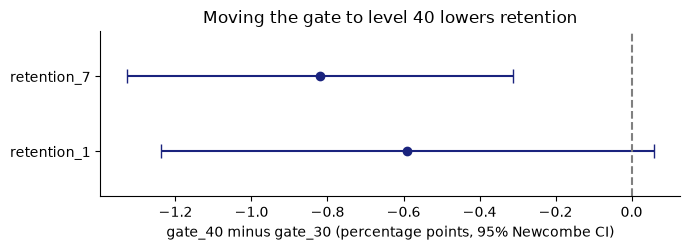

In [5]:
fig, ax = plt.subplots(figsize=(7, 2.6))
for i, (k, v) in enumerate(res.items()):
    ax.errorbar(v.diff*100, i, xerr=[[ (v.diff-v.ci_low)*100 ], [ (v.ci_high-v.diff)*100 ]], fmt='o', color='#1a237e', capsize=5)
ax.axvline(0, color='grey', ls='--'); ax.set_yticks([0, 1]); ax.set_yticklabels(list(res)); ax.set_ylim(-.6, 1.6)
ax.set_xlabel('gate_40 minus gate_30 (percentage points, 95% Newcombe CI)'); ax.set_title('Moving the gate to level 40 lowers retention')
ax.spines[['top','right']].set_visible(False); plt.tight_layout(); plt.savefig('images/effect_ci.png', dpi=130); plt.show()

## 4. Guardrail: engagement (heavy-tailed, so Mann-Whitney plus a bootstrap CI of the median difference)

In [6]:
a, b = df[df.version==A].sum_gamerounds.values, df[df.version==B].sum_gamerounds.values
print('max rounds:', df.sum_gamerounds.max(), '| p99:', df.sum_gamerounds.quantile(.99))
print('Mann-Whitney p =', round(mann_whitney(a, b), 4))
pt, lo, hi = bootstrap_diff(a, b, stat=np.median, n_boot=1000); print(f'median diff {pt:.1f} rounds, 95% CI [{lo:.1f}, {hi:.1f}]')
pt, lo, hi = bootstrap_diff(np.clip(a,0,np.quantile(a,.99)), np.clip(b,0,np.quantile(b,.99)), n_boot=1000)
print(f'mean diff (winsorised p99) {pt:.2f} rounds, 95% CI [{lo:.2f}, {hi:.2f}]')

max rounds: 49854 | p99: 493.0
Mann-Whitney p = 0.0502


median diff -1.0 rounds, 95% CI [-1.0, 0.0]


mean diff (winsorised p99) -0.29 rounds, 95% CI [-1.30, 0.71]


## 5. Segments: day-1 retained vs not (Holm-adjusted)
`retention_1` is measured after assignment, so segment effects are **conditional** on a post-treatment variable and are **not causal**. They are shown to locate where the overall difference shows up, not to target users.

In [7]:
seg = segment_table(df.assign(d1=df.retention_1.map({True:'day-1 retained', False:'not day-1 retained'})),
                    'version', 'retention_7', 'd1', A, B)
seg.round(4)

,d1,n_control,n_treatment,p_control,p_treatment,diff_pp,ci_low_pp,ci_high_pp,p_value,p_holm
0,day-1 retained,20034,20119,0.3332,0.3234,-0.9858,-1.9042,-0.0671,0.0354,0.0709
1,not day-1 retained,24666,25370,0.0740,0.0699,-0.4143,-0.8677,0.0385,0.0729,0.0729


## 6. Pitfall: peeking. A/A simulation at this test's baseline and size, with 10 interim looks

In [8]:
fixed, peek = peeking_false_positive_rate(base7, int(n.min()), looks=10, sims=2000)
print(f'False-positive rate: fixed horizon {fixed:.3f} | stop at first significant look {peek:.3f}')

False-positive rate: fixed horizon 0.048 | stop at first significant look 0.197


## Decision
- **SRM check fails** (chi2 = 6.90, p = 0.0086): gate_40 has 789 more players, a 50.4/49.6 split. Assignment or logging is imbalanced, so the effect estimate is not fully trustworthy. The first action is to audit assignment.
- **Conditional on that audit, keep gate_30.** Day-7 retention is 0.82 pp lower under gate_40 (95% CI [-1.33, -0.31], p = 0.0016). That exceeds the 0.74 pp MDE, so the test was adequately powered for this size of effect. Day-1 retention is -0.59 pp, with a CI that includes 0.
- **Guardrail:** engagement shows no significant shift (Mann-Whitney p = 0.050; winsorised mean difference CI [-1.30, 0.71] rounds).
- **Peeking:** with 10 interim looks, the false-positive rate rises from 4.8% to 19.7%. Analyse once, at the planned sample size.